In [1]:
from importlib import reload
import TRECCASTeval as trec
import OpenSearchSimpleAPI as osearch
from retrieval_methods.LMD import LMD_Retrieval

import pprint as pp

osearch = reload(osearch)
trec = reload(trec)

lmd = LMD_Retrieval

opensearch = osearch.OSsimpleAPI()
test_bed = trec.ConvSearchEvaluation()
conv_topics = test_bed.train_topics

In [2]:
conv_topic_idx = 0

topic = conv_topics[conv_topic_idx]

turn = topic['turn'][7]
turn_id = turn['number']
utterance = turn['raw_utterance']
print(utterance)


result = lmd.retrieve_fun(opensearch,utterance,200)

What the difference between a PA and a nurse practitioner?
['MARCO_6311185', 'MARCO_7090806', 'MARCO_2849832', 'MARCO_3600884', 'MARCO_7514658', 'MARCO_8579371', 'MARCO_888704', 'MARCO_1908383', 'MARCO_168924', 'MARCO_3144856', 'MARCO_6312729', 'MARCO_4077804', 'MARCO_5407409', 'MARCO_7496118', 'MARCO_3984229', 'MARCO_1908384', 'MARCO_7446928', 'CAR_436ad602db45c2c05a6f1d2b9461f20e8400e60a', 'MARCO_5893872', 'MARCO_5699123', 'MARCO_3951096', 'MARCO_5673918', 'MARCO_6816116', 'MARCO_615449', 'CAR_a1abdc7279a2178f62a20792a69b6bdb95731eea', 'MARCO_1505116', 'MARCO_3984224', 'MARCO_6607048', 'MARCO_6244208', 'MARCO_2904127', 'MARCO_2307794', 'MARCO_4225982', 'MARCO_6311397', 'MARCO_4003509', 'MARCO_364098', 'MARCO_8407876', 'MARCO_4014355', 'MARCO_8716240', 'MARCO_2483667', 'MARCO_5787541', 'MARCO_291620', 'MARCO_7560829', 'MARCO_8503215', 'MARCO_3768527', 'MARCO_2596754', 'MARCO_1827628', 'MARCO_6607056', 'MARCO_6607051', 'MARCO_7342285', 'MARCO_8824030', 'MARCO_3860555', 'MARCO_4518595',

In [3]:
print(result)

                                              _id     _score  \
0                                   MARCO_6311185 -37.655107   
1                                   MARCO_7090806 -39.050118   
2                                   MARCO_2849832 -39.341187   
3                                   MARCO_7514658 -39.952613   
4                                   MARCO_3600884 -43.978987   
..                                            ...        ...   
195                                 MARCO_4847842 -69.825960   
196                                   MARCO_62926 -69.973198   
197                                 MARCO_5604435 -70.994448   
198  CAR_4d4e149f7b51d26af25203d7b69b6dae853f05b9 -73.007611   
199  CAR_eac4c13d758d330e97e60846c09b7df81eb1a404 -73.628529   

                                      _source.doc  
0                                   MARCO_6311185  
1                                   MARCO_7090806  
2                                   MARCO_2849832  
3                      

In [4]:
top_doc = result.iloc[1]
top_doc_body = opensearch.get_doc_body(top_doc._id)
print("TOP DOCUMENT:")
print("-" + top_doc_body)

#bottom_doc = result.iloc[198]
bottom_doc = result.iloc[170]
bottom_doc_body = opensearch.get_doc_body(bottom_doc._id)

print("BOTTOM DOCUMENT:")
print("-" + bottom_doc_body)


TOP DOCUMENT:
-The Difference Between a Nurse Practitioner (NP) and a Physician Assistant (PA) As many patients know, people rarely see a medical doctor for routine physical examinations anymore. They are far more likely to have an appointment with a Nurse Practitioner (NP) or Physician Assistant (PA) who works in the practice.
BOTTOM DOCUMENT:
-Sand tiger shark. Not to be confused with sand shark, tiger shark, or nurse shark. The sand tiger shark (Carcharias taurus), grey nurse shark, spotted ragged-tooth shark, or blue-nurse sand tiger is a species of shark that inhabits subtropical and temperate waters worldwide.


In [5]:
from sentence_transformers import SentenceTransformer


# Load Dual-Encoder
dual_encoder_path = "sentence-transformers/multi-qa-MiniLM-L6-cos-v1"
dual_encoder = SentenceTransformer(dual_encoder_path)

In [6]:
from transformers import AutoTokenizer, AutoModel, AutoConfig

dual_encoder_tokenizer = AutoTokenizer.from_pretrained(dual_encoder_path)
dual_encoder_config = AutoConfig.from_pretrained(dual_encoder_path, output_hidden_states=True, output_attentions=True)
dual_encoder_model = AutoModel.from_pretrained(dual_encoder_path, config=dual_encoder_config)

## FOR POSITIVE


In [7]:
#ACHO QUE SO FAZ SENTIDO A PARTIR DAQUI
#(os acima são desnecessários) acho que é possivel juntar tudo

dual_encoder_POS = dual_encoder_tokenizer(utterance, top_doc_body, return_tensors='pt', max_length=512, truncation=True, padding=True)

# Decode combined tokens

print("Decoded Positive Pair:")
print(dual_encoder_tokenizer.decode(dual_encoder_POS["input_ids"][0]))


# Convert input IDs to token list for the query

input_ids_POS = dual_encoder_POS['input_ids']
input_ids_POS_list = input_ids_POS[0].tolist()
input_tokens_POS_list = dual_encoder_tokenizer.convert_ids_to_tokens(input_ids_POS_list)
print("Query Tokens:")
print(input_tokens_POS_list) 

Decoded Positive Pair:
[CLS] what the difference between a pa and a nurse practitioner? [SEP] the difference between a nurse practitioner ( np ) and a physician assistant ( pa ) as many patients know, people rarely see a medical doctor for routine physical examinations anymore. they are far more likely to have an appointment with a nurse practitioner ( np ) or physician assistant ( pa ) who works in the practice. [SEP]
Query Tokens:
['[CLS]', 'what', 'the', 'difference', 'between', 'a', 'pa', 'and', 'a', 'nurse', 'practitioner', '?', '[SEP]', 'the', 'difference', 'between', 'a', 'nurse', 'practitioner', '(', 'np', ')', 'and', 'a', 'physician', 'assistant', '(', 'pa', ')', 'as', 'many', 'patients', 'know', ',', 'people', 'rarely', 'see', 'a', 'medical', 'doctor', 'for', 'routine', 'physical', 'examinations', 'anymore', '.', 'they', 'are', 'far', 'more', 'likely', 'to', 'have', 'an', 'appointment', 'with', 'a', 'nurse', 'practitioner', '(', 'np', ')', 'or', 'physician', 'assistant', '(',

In [8]:
res_POS = "\n".join("{} \t {}".format(x, y) for x, y in zip(input_ids_POS_list, input_tokens_POS_list))
print(res_POS)



101 	 [CLS]
2054 	 what
1996 	 the
4489 	 difference
2090 	 between
1037 	 a
6643 	 pa
1998 	 and
1037 	 a
6821 	 nurse
18742 	 practitioner
1029 	 ?
102 	 [SEP]
1996 	 the
4489 	 difference
2090 	 between
1037 	 a
6821 	 nurse
18742 	 practitioner
1006 	 (
27937 	 np
1007 	 )
1998 	 and
1037 	 a
7522 	 physician
3353 	 assistant
1006 	 (
6643 	 pa
1007 	 )
2004 	 as
2116 	 many
5022 	 patients
2113 	 know
1010 	 ,
2111 	 people
6524 	 rarely
2156 	 see
1037 	 a
2966 	 medical
3460 	 doctor
2005 	 for
9410 	 routine
3558 	 physical
14912 	 examinations
4902 	 anymore
1012 	 .
2027 	 they
2024 	 are
2521 	 far
2062 	 more
3497 	 likely
2000 	 to
2031 	 have
2019 	 an
6098 	 appointment
2007 	 with
1037 	 a
6821 	 nurse
18742 	 practitioner
1006 	 (
27937 	 np
1007 	 )
2030 	 or
7522 	 physician
3353 	 assistant
1006 	 (
6643 	 pa
1007 	 )
2040 	 who
2573 	 works
1999 	 in
1996 	 the
3218 	 practice
1012 	 .
102 	 [SEP]


In [9]:
import torch

with torch.no_grad():
    outputs = dual_encoder_model(**dual_encoder_POS)

attention = outputs.attentions
hidden_states = outputs.hidden_states


first_layer_embeddings = hidden_states[0][0]  
last_layer_embeddings = hidden_states[-1][0]  


first_10_tokens_first_layer = first_layer_embeddings[:10].detach().numpy()
first_10_tokens_last_layer = last_layer_embeddings[:10].detach().numpy()

BertSdpaSelfAttention is used but `torch.nn.functional.scaled_dot_product_attention` does not support non-absolute `position_embedding_type` or `output_attentions=True` or `head_mask`. Falling back to the manual attention implementation, but specifying the manual implementation will be required from Transformers version v5.0.0 onwards. This warning can be removed using the argument `attn_implementation="eager"` when loading the model.


In [10]:
import matplotlib.pyplot as plt
plt.style.use('ggplot')

# 
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA

def display_scatterplot(data, words):

    if data.shape[1] == 2:
        twodim = data
    else:
        pca = PCA()
        pca.fit(data)
        twodim = pca.transform(data)[:,:2]
    
    plt.style.use('default') # https://matplotlib.org/3.5.1/gallery/style_sheets/style_sheets_reference.html
    plt.figure(figsize=(6,6))
    plt.scatter(twodim[:,0], twodim[:,1], edgecolors='k', c='r')
    for word, (x,y) in zip(words, twodim):
        plt.text(x+0.05, y+0.05, word)

    return

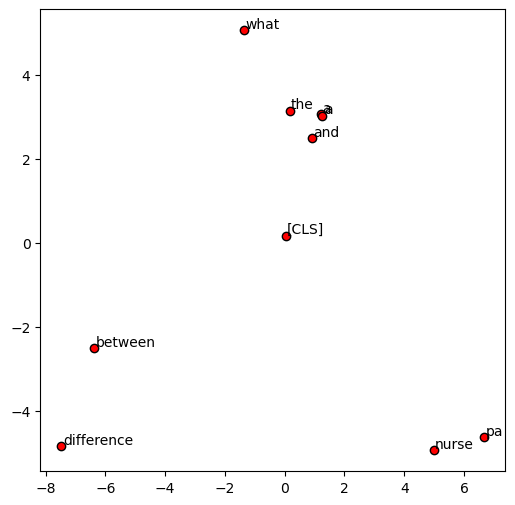

In [11]:
#Plot the token embeddings of the first-layer  
display_scatterplot(first_10_tokens_first_layer, input_tokens_POS_list[:10])

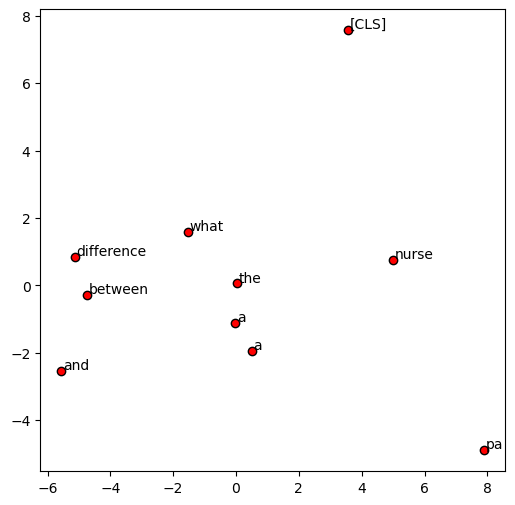

In [12]:
#Plot the token embeddings of the last-layer 
display_scatterplot(first_10_tokens_last_layer, input_tokens_POS_list[:10])

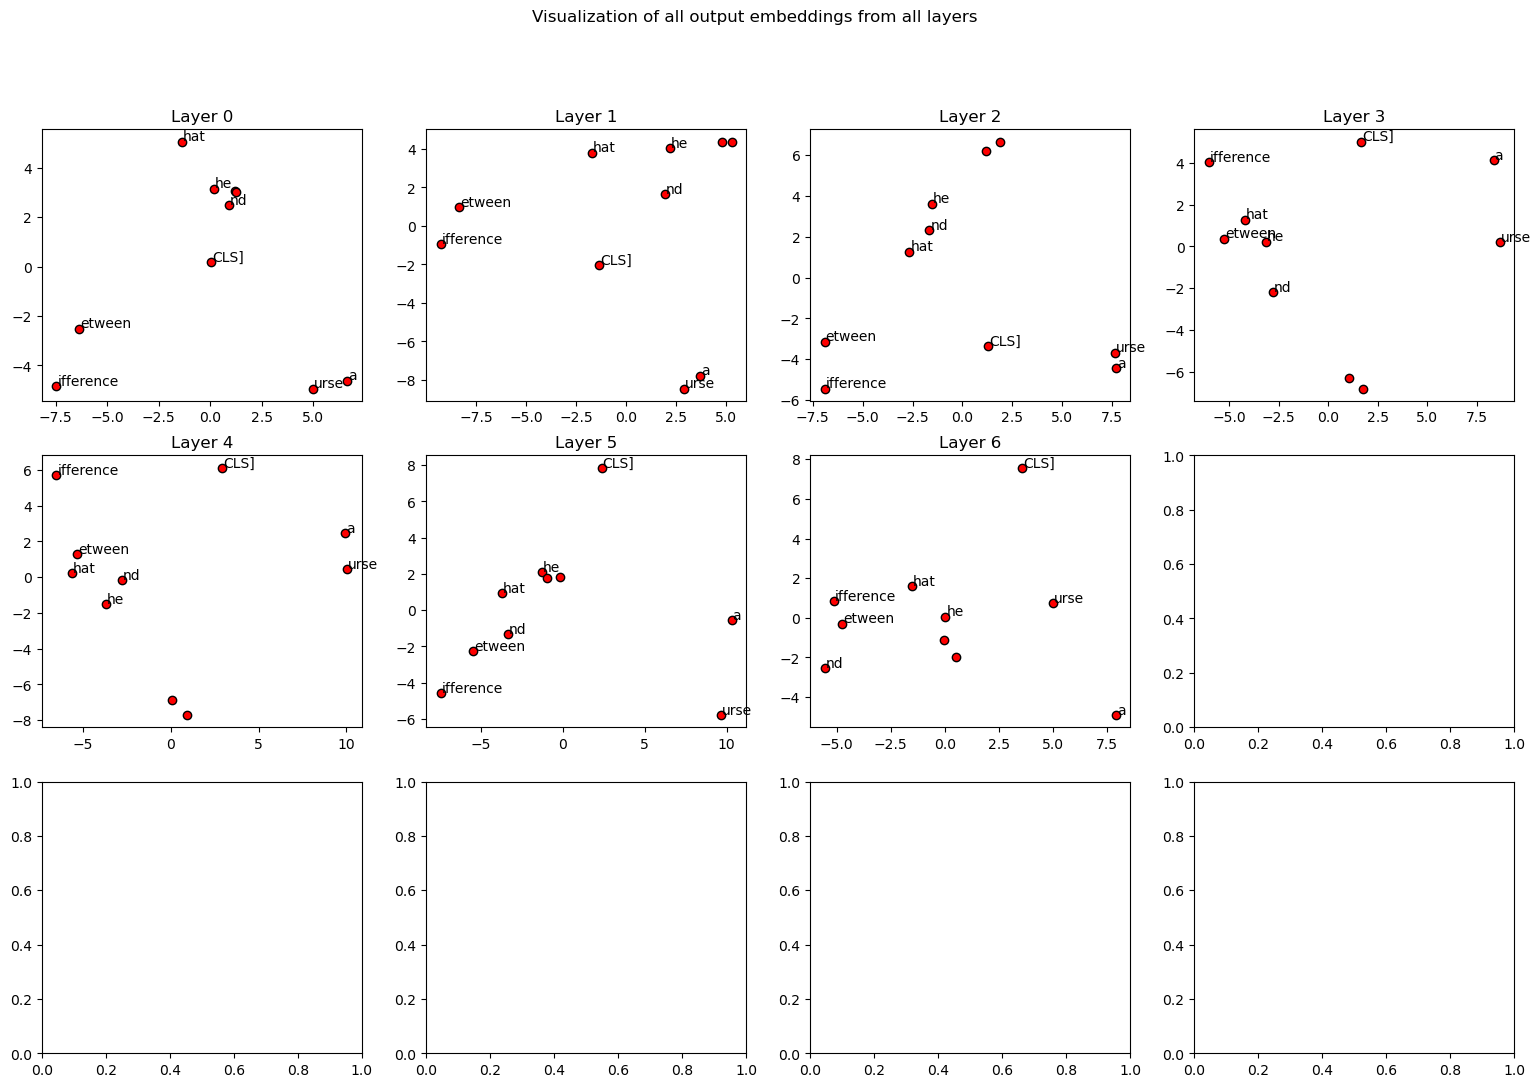

In [16]:
#REPEAT FOR ALL

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

layer = 1

rows = 3
cols = 4
fig, ax_full = plt.subplots(rows, cols)
fig.set_figheight(rows*4)
fig.set_figwidth(cols*4+3)
plt.rcParams.update({'font.size': 6})


layer = 0
for r in range(rows):
    for c in range(cols):
        if layer >= len(hidden_states): 
            break
       
        ax = ax_full[r,c]
        
        plt.rcParams.update({'font.size': 10})
        current_hidden_state = hidden_states[layer][0].detach().numpy()

        current_hidden_state = current_hidden_state[:10]
        
        if current_hidden_state.shape[1] == 2:
            twodim = current_hidden_state
        else:
            twodim = PCA().fit_transform(current_hidden_state)[:,:2]

        plt.style.use('default') # https://matplotlib.org/3.5.1/gallery/style_sheets/style_sheets_reference.html
        im = ax.scatter(twodim[:,0], twodim[:,1], edgecolors='k', c='r')
        for word, (x,y) in zip(input_tokens_POS_list, twodim):
            ax.text(x+0.05, y+0.05, word[1:])
        
        # Show all ticks and label them with the respective list entries
        ax.set_title("Layer " + str(layer))
            
        # Loop over data dimensions and create text annotations.
        layer = layer + 1

fig.suptitle("Visualization of all output embeddings from all layers")
fig.savefig("self-att-visualizations/EmbeddingsDual-POS.png")
plt.show()


In [14]:
#SIMILARITY

with torch.no_grad():
    outputs = dual_encoder_model(**dual_encoder_POS)

attention = outputs.attentions
hidden_states = outputs.hidden_states


first_layer_embeddings = hidden_states[0][0]  
last_layer_embeddings = hidden_states[-1][0]  


first_10_tokens_first_layer = first_layer_embeddings[:10].detach().numpy()
first_10_tokens_last_layer = last_layer_embeddings[:10].detach().numpy()

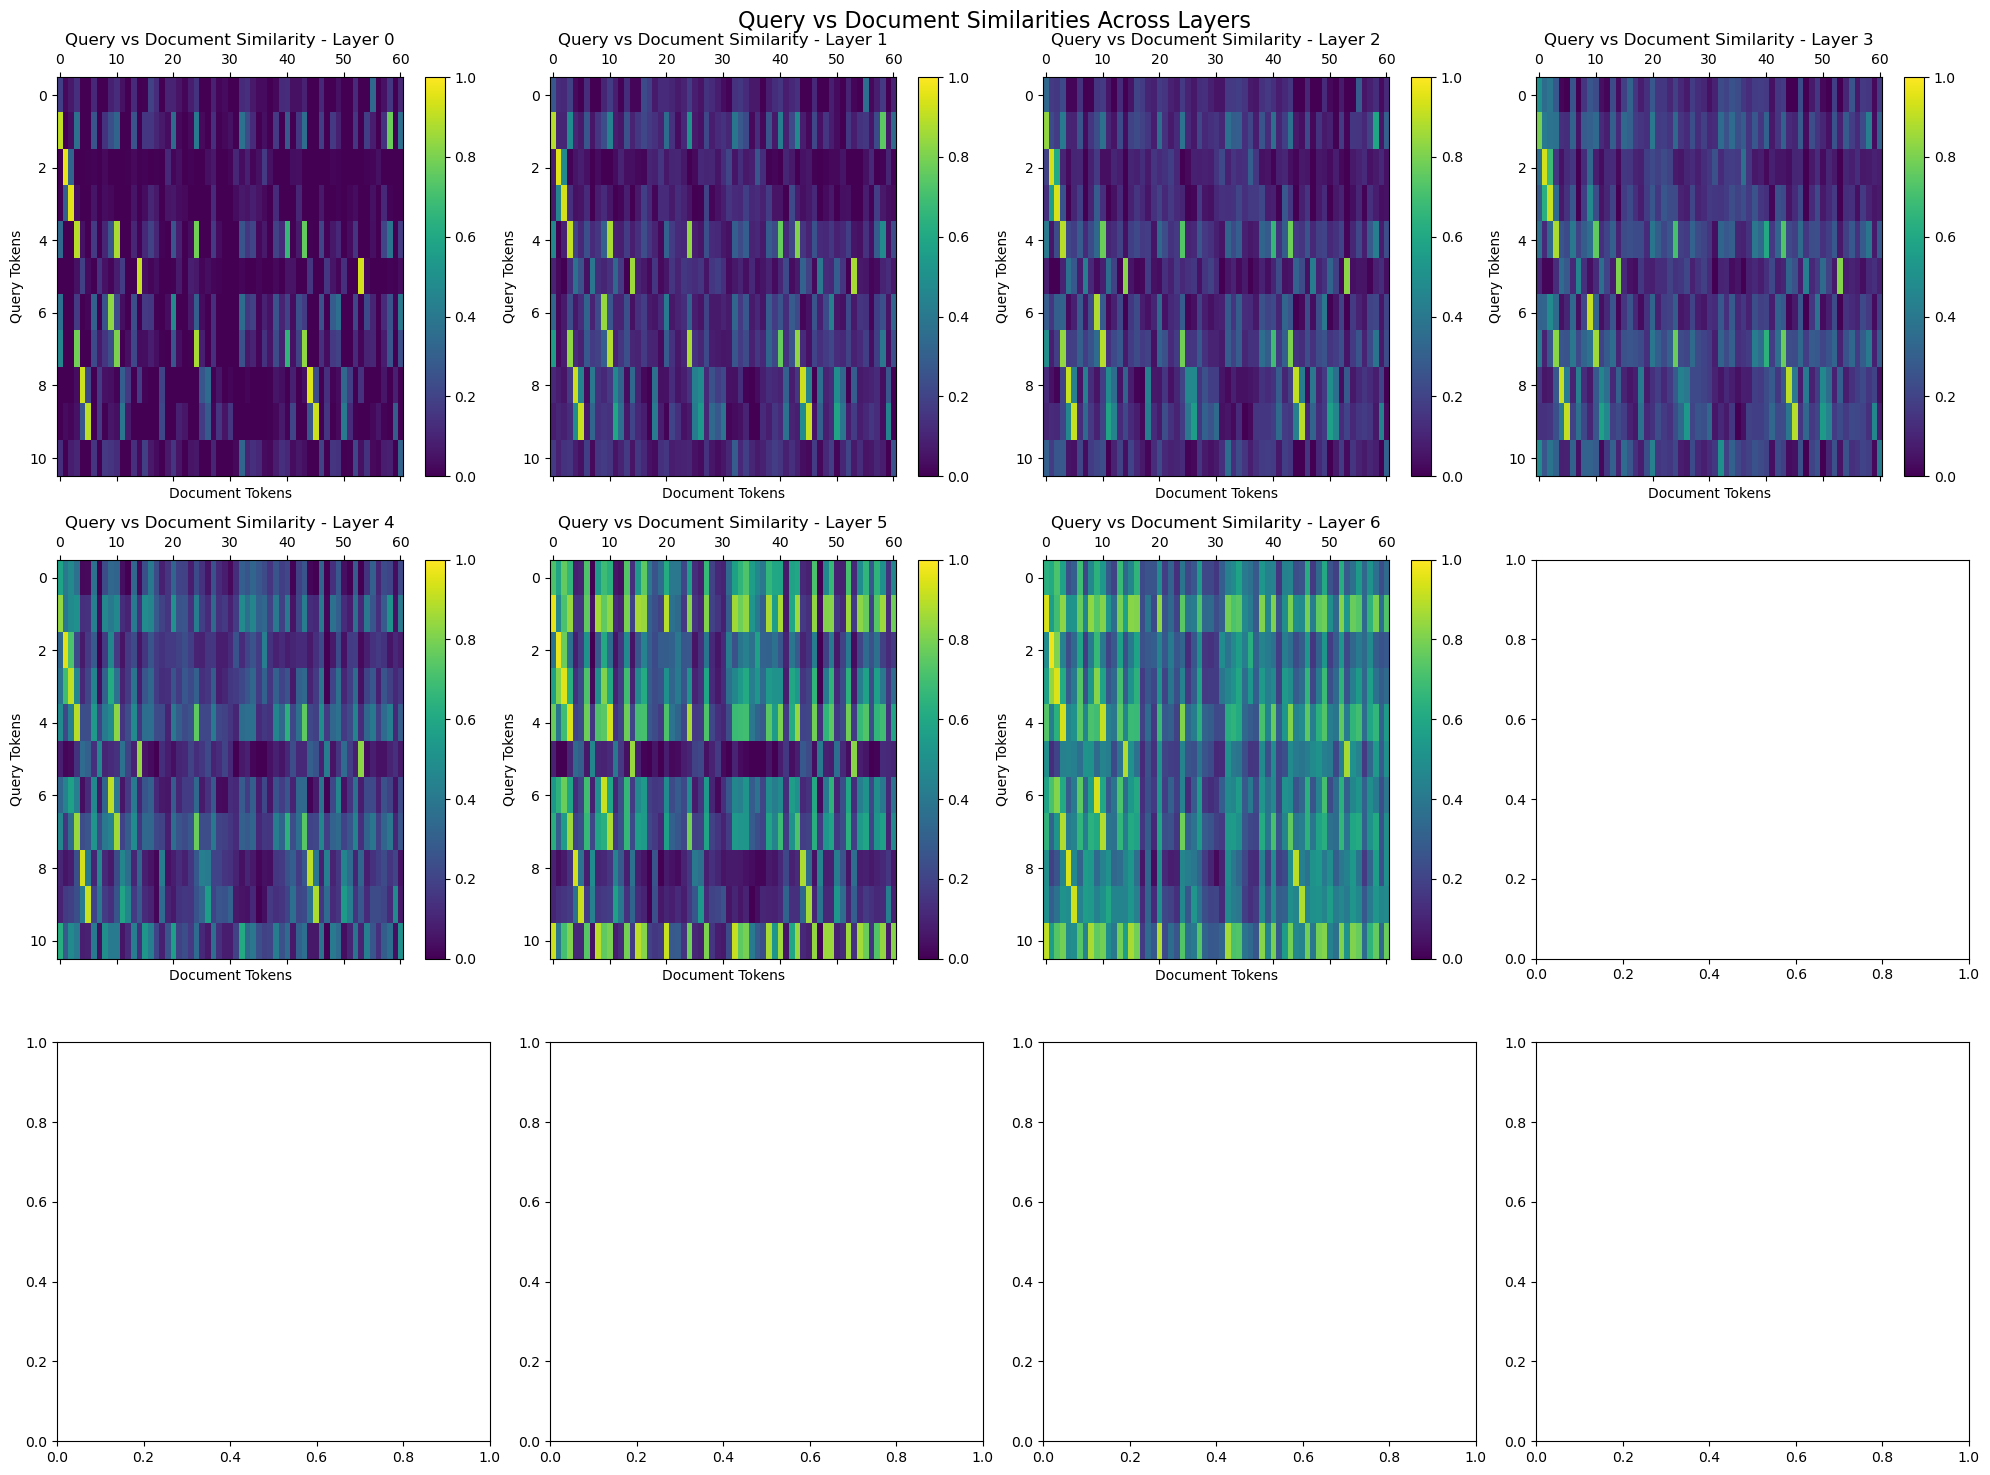

In [15]:
# Determine indices of query and document tokens
sep_token_id = dual_encoder_tokenizer.sep_token_id 
input_ids_POS_list = input_ids_POS[0].tolist()    

query_indices = range(1, input_ids_POS_list.index(sep_token_id))  


doc_indices = range(input_ids_POS_list.index(sep_token_id) + 1, len(input_ids_POS_list) - 1)

from sklearn.metrics.pairwise import cosine_similarity


similarities = []

for layer in range(len(hidden_states)):
    layer_embeddings = hidden_states[layer][0].detach().numpy()
    query_embeddings = layer_embeddings[query_indices]
    doc_embeddings = layer_embeddings[doc_indices]

    # Compute similarity matrix
    similarity_matrix = cosine_similarity(query_embeddings, doc_embeddings)
    similarities.append(similarity_matrix)


import matplotlib.pyplot as plt
import numpy as np


rows, cols = 3, 4  
fig, ax_full = plt.subplots(rows, cols, figsize=(20, 15))

layer = 0
for r in range(rows):
    for c in range(cols):
        if layer >= len(similarities):  
            break
        
        ax = ax_full[r, c]
        similarity_matrix = similarities[layer]
        
    
        cax = ax.matshow(similarity_matrix, cmap="viridis", aspect='auto', vmin=0, vmax=1)

        ax.set_title(f"Query vs Document Similarity - Layer {layer}")
        ax.set_xlabel("Document Tokens")
        ax.set_ylabel("Query Tokens")
        
        fig.colorbar(cax, ax=ax)

        layer += 1

plt.suptitle("Query vs Document Similarities Across Layers", fontsize=16)
plt.tight_layout()
plt.show()
fig.savefig("self-att-visualizations/SimilarityDual-POS.png")

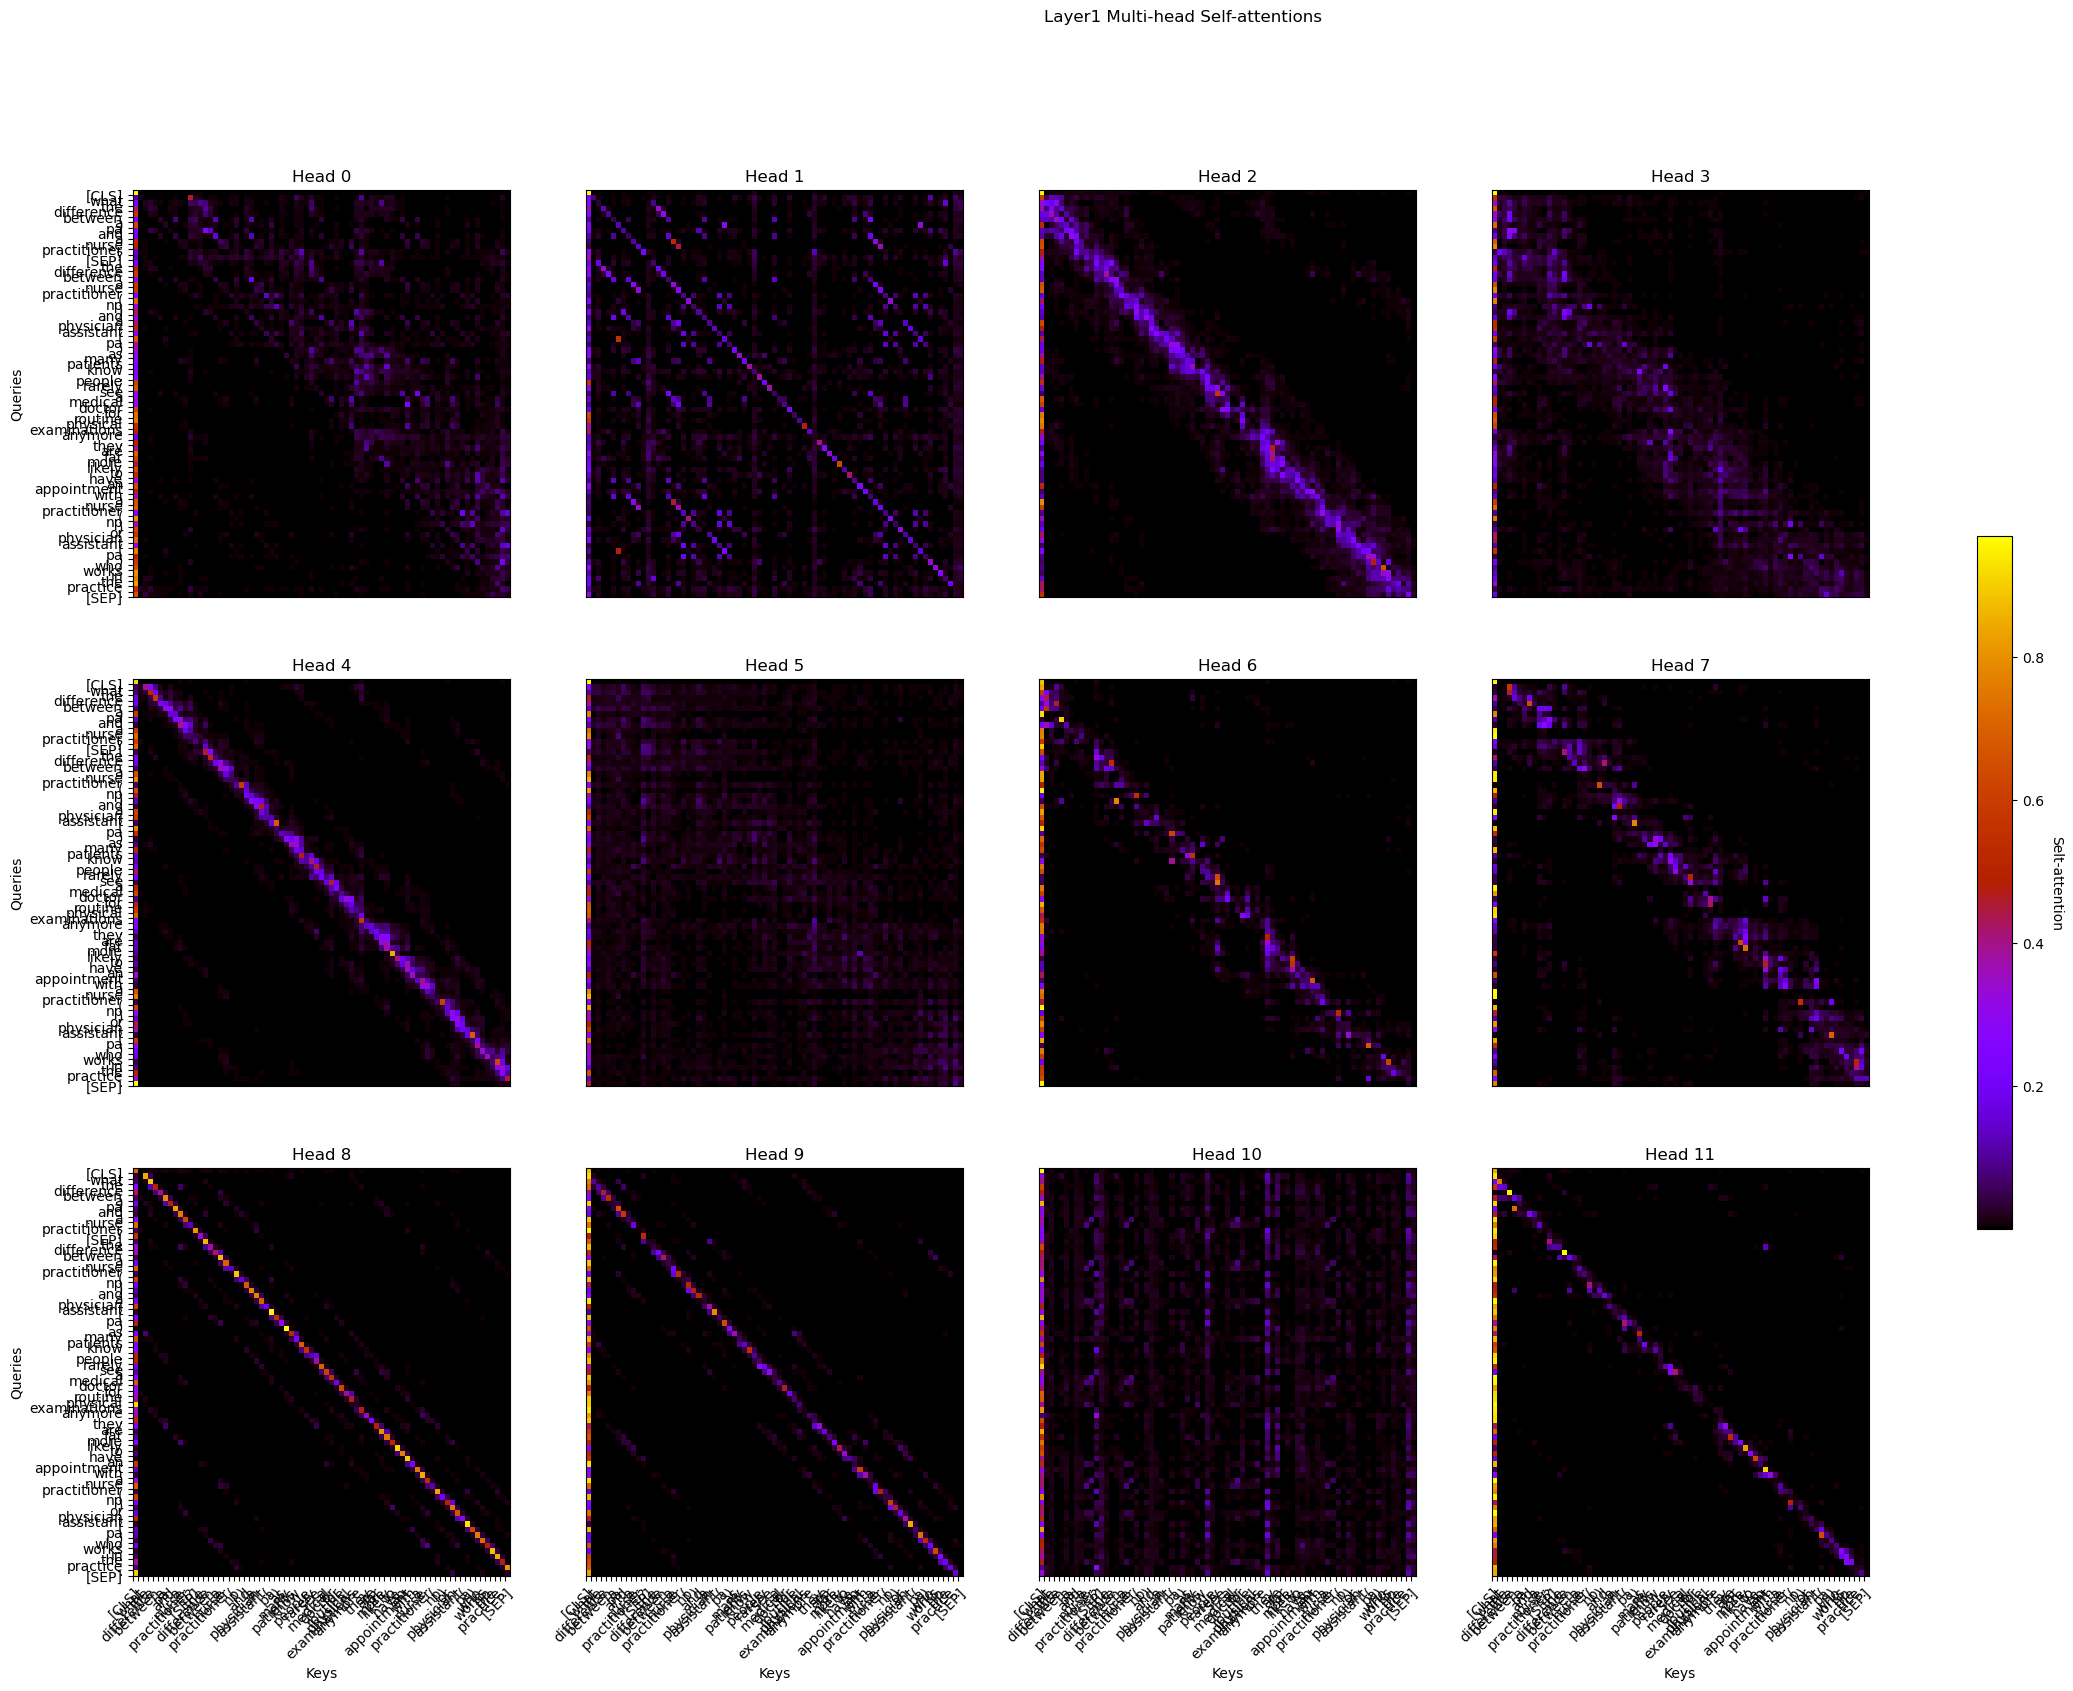

In [17]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

layer = 1

rows = 3
cols = 4
fig, ax_full = plt.subplots(rows, cols)
fig.set_figheight(rows*6)
fig.set_figwidth(cols*6+4)
plt.rcParams.update({'font.size': 10})


j = 0
for r in range(rows):
    for c in range(cols):
        
        ax = ax_full[r,c]
        
        sattention = attention[layer][0][j].numpy()
        sattention = np.flip(sattention, 0)
        
        plt.rcParams.update({'font.size': 10})

        im = ax.pcolormesh(sattention, cmap='gnuplot')

        # Show all ticks and label them with the respective list entries
        ax.set_title("Head " + str(j))
        ax.set_yticks(np.arange(len(input_tokens_POS_list)))
        if c == 0:
            ax.set_yticklabels(reversed(input_tokens_POS_list))
            ax.set_ylabel("Queries")
        else:
            ax.set_yticks([])

        ax.set_xticks(np.arange(len(input_tokens_POS_list)))
        if r == rows-1:
            ax.set_xticklabels(input_tokens_POS_list)
            ax.set_xlabel("Keys")
            
            # Rotate the tick labels and set their alignment.
            plt.setp(ax.get_xticklabels(), rotation=45, ha="right",
                     rotation_mode="anchor")
        else:
            ax.set_xticks([])

            
        # Loop over data dimensions and create text annotations.
        j = j + 1

fig.suptitle("Layer" + str(layer) + " Multi-head Self-attentions")
cbar = fig.colorbar(im, ax=ax_full, location='right', shrink=0.5)
cbar.ax.set_ylabel("Selt-attention", rotation=-90, va="bottom")

#plt.figure(figsize=(x,y))

plt.show()
fig.savefig("self-att-visualizations/HeadVisualizationDual-POS.png")


## FOR NEGATIVE



In [18]:


dual_encoder_NEG = dual_encoder_tokenizer(utterance, bottom_doc_body, return_tensors='pt', max_length=512, truncation=True, padding=True)

# Decode combined tokens


print("Decoded Positive Pair:")
print(dual_encoder_tokenizer.decode(dual_encoder_NEG["input_ids"][0]))


# Convert input IDs to token list for the query

input_ids_NEG = dual_encoder_NEG['input_ids']
input_ids_NEG_list = input_ids_NEG[0].tolist()
input_tokens_NEG_list = dual_encoder_tokenizer.convert_ids_to_tokens(input_ids_NEG_list)
print("Query Tokens:")
print(input_tokens_NEG_list) 

Decoded Positive Pair:
[CLS] what the difference between a pa and a nurse practitioner? [SEP] sand tiger shark. not to be confused with sand shark, tiger shark, or nurse shark. the sand tiger shark ( carcharias taurus ), grey nurse shark, spotted ragged - tooth shark, or blue - nurse sand tiger is a species of shark that inhabits subtropical and temperate waters worldwide. [SEP]
Query Tokens:
['[CLS]', 'what', 'the', 'difference', 'between', 'a', 'pa', 'and', 'a', 'nurse', 'practitioner', '?', '[SEP]', 'sand', 'tiger', 'shark', '.', 'not', 'to', 'be', 'confused', 'with', 'sand', 'shark', ',', 'tiger', 'shark', ',', 'or', 'nurse', 'shark', '.', 'the', 'sand', 'tiger', 'shark', '(', 'car', '##cha', '##ria', '##s', 'tau', '##rus', ')', ',', 'grey', 'nurse', 'shark', ',', 'spotted', 'ragged', '-', 'tooth', 'shark', ',', 'or', 'blue', '-', 'nurse', 'sand', 'tiger', 'is', 'a', 'species', 'of', 'shark', 'that', 'inhabit', '##s', 'subtropical', 'and', 'temperate', 'waters', 'worldwide', '.', '

In [19]:
res_NEG = "\n".join("{} \t {}".format(x, y) for x, y in zip(input_ids_NEG_list, input_tokens_NEG_list))
print(res_NEG)

101 	 [CLS]
2054 	 what
1996 	 the
4489 	 difference
2090 	 between
1037 	 a
6643 	 pa
1998 	 and
1037 	 a
6821 	 nurse
18742 	 practitioner
1029 	 ?
102 	 [SEP]
5472 	 sand
6816 	 tiger
11420 	 shark
1012 	 .
2025 	 not
2000 	 to
2022 	 be
5457 	 confused
2007 	 with
5472 	 sand
11420 	 shark
1010 	 ,
6816 	 tiger
11420 	 shark
1010 	 ,
2030 	 or
6821 	 nurse
11420 	 shark
1012 	 .
1996 	 the
5472 	 sand
6816 	 tiger
11420 	 shark
1006 	 (
2482 	 car
7507 	 ##cha
4360 	 ##ria
2015 	 ##s
19982 	 tau
7946 	 ##rus
1007 	 )
1010 	 ,
4462 	 grey
6821 	 nurse
11420 	 shark
1010 	 ,
7282 	 spotted
14202 	 ragged
1011 	 -
11868 	 tooth
11420 	 shark
1010 	 ,
2030 	 or
2630 	 blue
1011 	 -
6821 	 nurse
5472 	 sand
6816 	 tiger
2003 	 is
1037 	 a
2427 	 species
1997 	 of
11420 	 shark
2008 	 that
21490 	 inhabit
2015 	 ##s
11935 	 subtropical
1998 	 and
16868 	 temperate
5380 	 waters
4969 	 worldwide
1012 	 .
102 	 [SEP]


In [20]:
import torch

with torch.no_grad():
    outputs_NEG = dual_encoder_model(**dual_encoder_NEG)

attention_NEG = outputs_NEG.attentions
hidden_states_NEG = outputs_NEG.hidden_states


first_layer_embeddings_NEG = hidden_states_NEG[0][0]  
last_layer_embeddings_NEG = hidden_states_NEG[-1][0]  


first_10_tokens_first_layer_NEG = first_layer_embeddings_NEG[:10].detach().numpy()
first_10_tokens_last_layer_NEG = last_layer_embeddings_NEG[:10].detach().numpy()

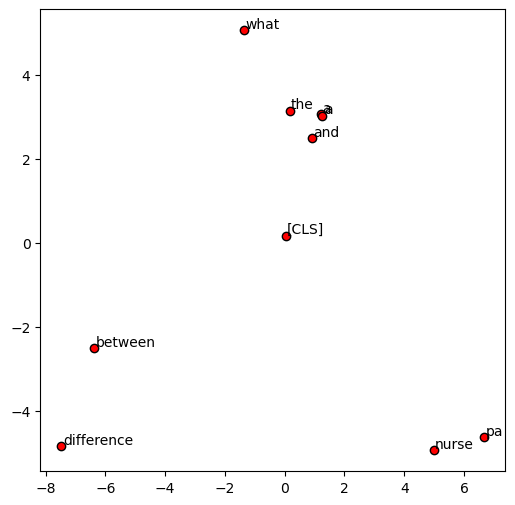

In [21]:
#Plot the token embeddings of the first-layer  
display_scatterplot(first_10_tokens_first_layer_NEG, input_tokens_NEG_list[:10])

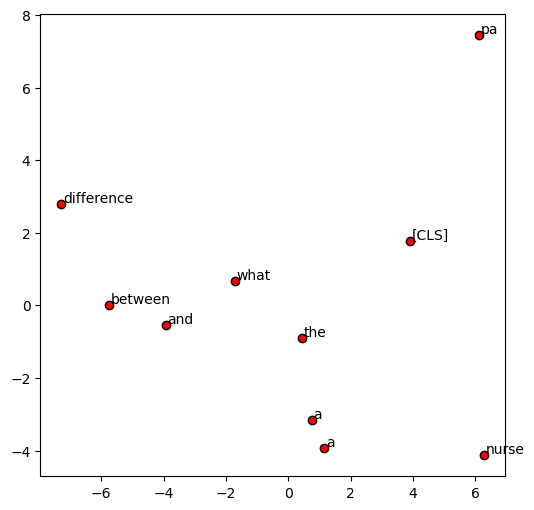

In [22]:
#Plot the token embeddings of the last-layer 
display_scatterplot(first_10_tokens_last_layer_NEG, input_tokens_NEG_list[:10])

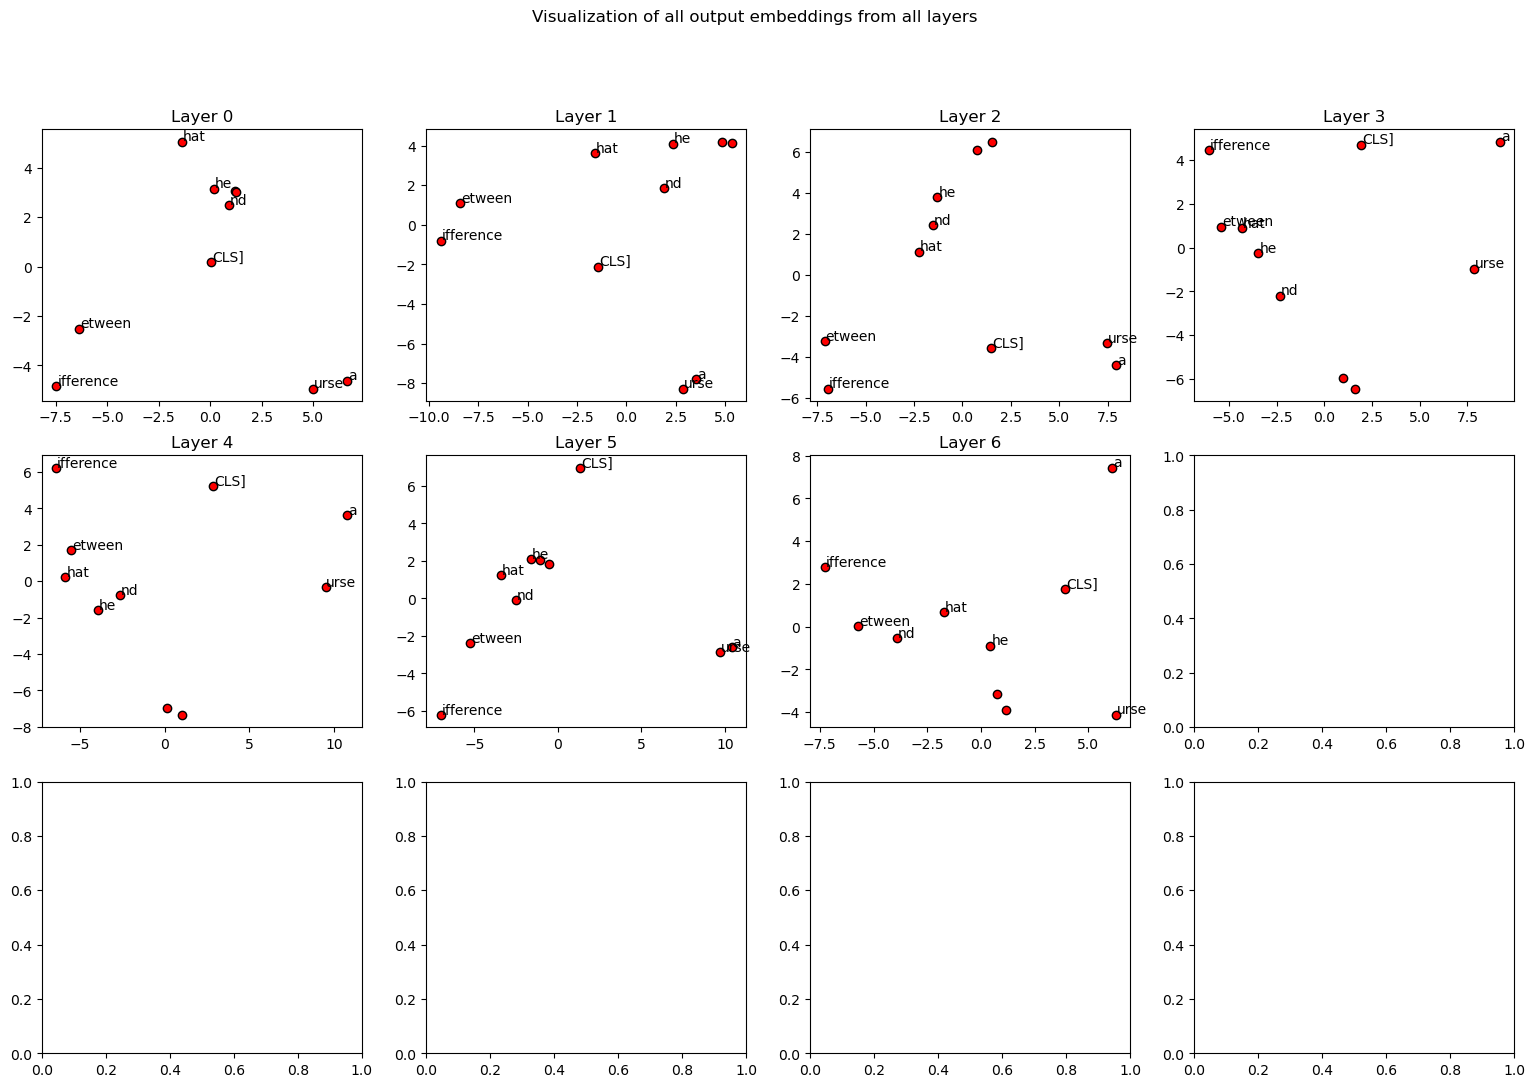

In [23]:
#REPEAT FOR ALL

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

layer = 1

rows = 3
cols = 4
fig, ax_full = plt.subplots(rows, cols)
fig.set_figheight(rows*4)
fig.set_figwidth(cols*4+3)
plt.rcParams.update({'font.size': 6})


layer = 0
for r in range(rows):
    for c in range(cols):
        if layer >= len(hidden_states_NEG): 
            break
       
        ax = ax_full[r,c]
        
        plt.rcParams.update({'font.size': 10})
        current_hidden_state_NEG = hidden_states_NEG[layer][0].detach().numpy()

        current_hidden_state_NEG = current_hidden_state_NEG[:10]
        
        if current_hidden_state_NEG.shape[1] == 2:
            twodim = current_hidden_state_NEG
        else:
            twodim = PCA().fit_transform(current_hidden_state_NEG)[:,:2]

        plt.style.use('default') # https://matplotlib.org/3.5.1/gallery/style_sheets/style_sheets_reference.html
        im = ax.scatter(twodim[:,0], twodim[:,1], edgecolors='k', c='r')
        for word, (x,y) in zip(input_tokens_NEG_list, twodim):
            ax.text(x+0.05, y+0.05, word[1:])
        
        # Show all ticks and label them with the respective list entries
        ax.set_title("Layer " + str(layer))
            
        # Loop over data dimensions and create text annotations.
        layer = layer + 1

fig.suptitle("Visualization of all output embeddings from all layers")
plt.show()
fig.savefig("self-att-visualizations/EmbeddingsDual-NEG.png")

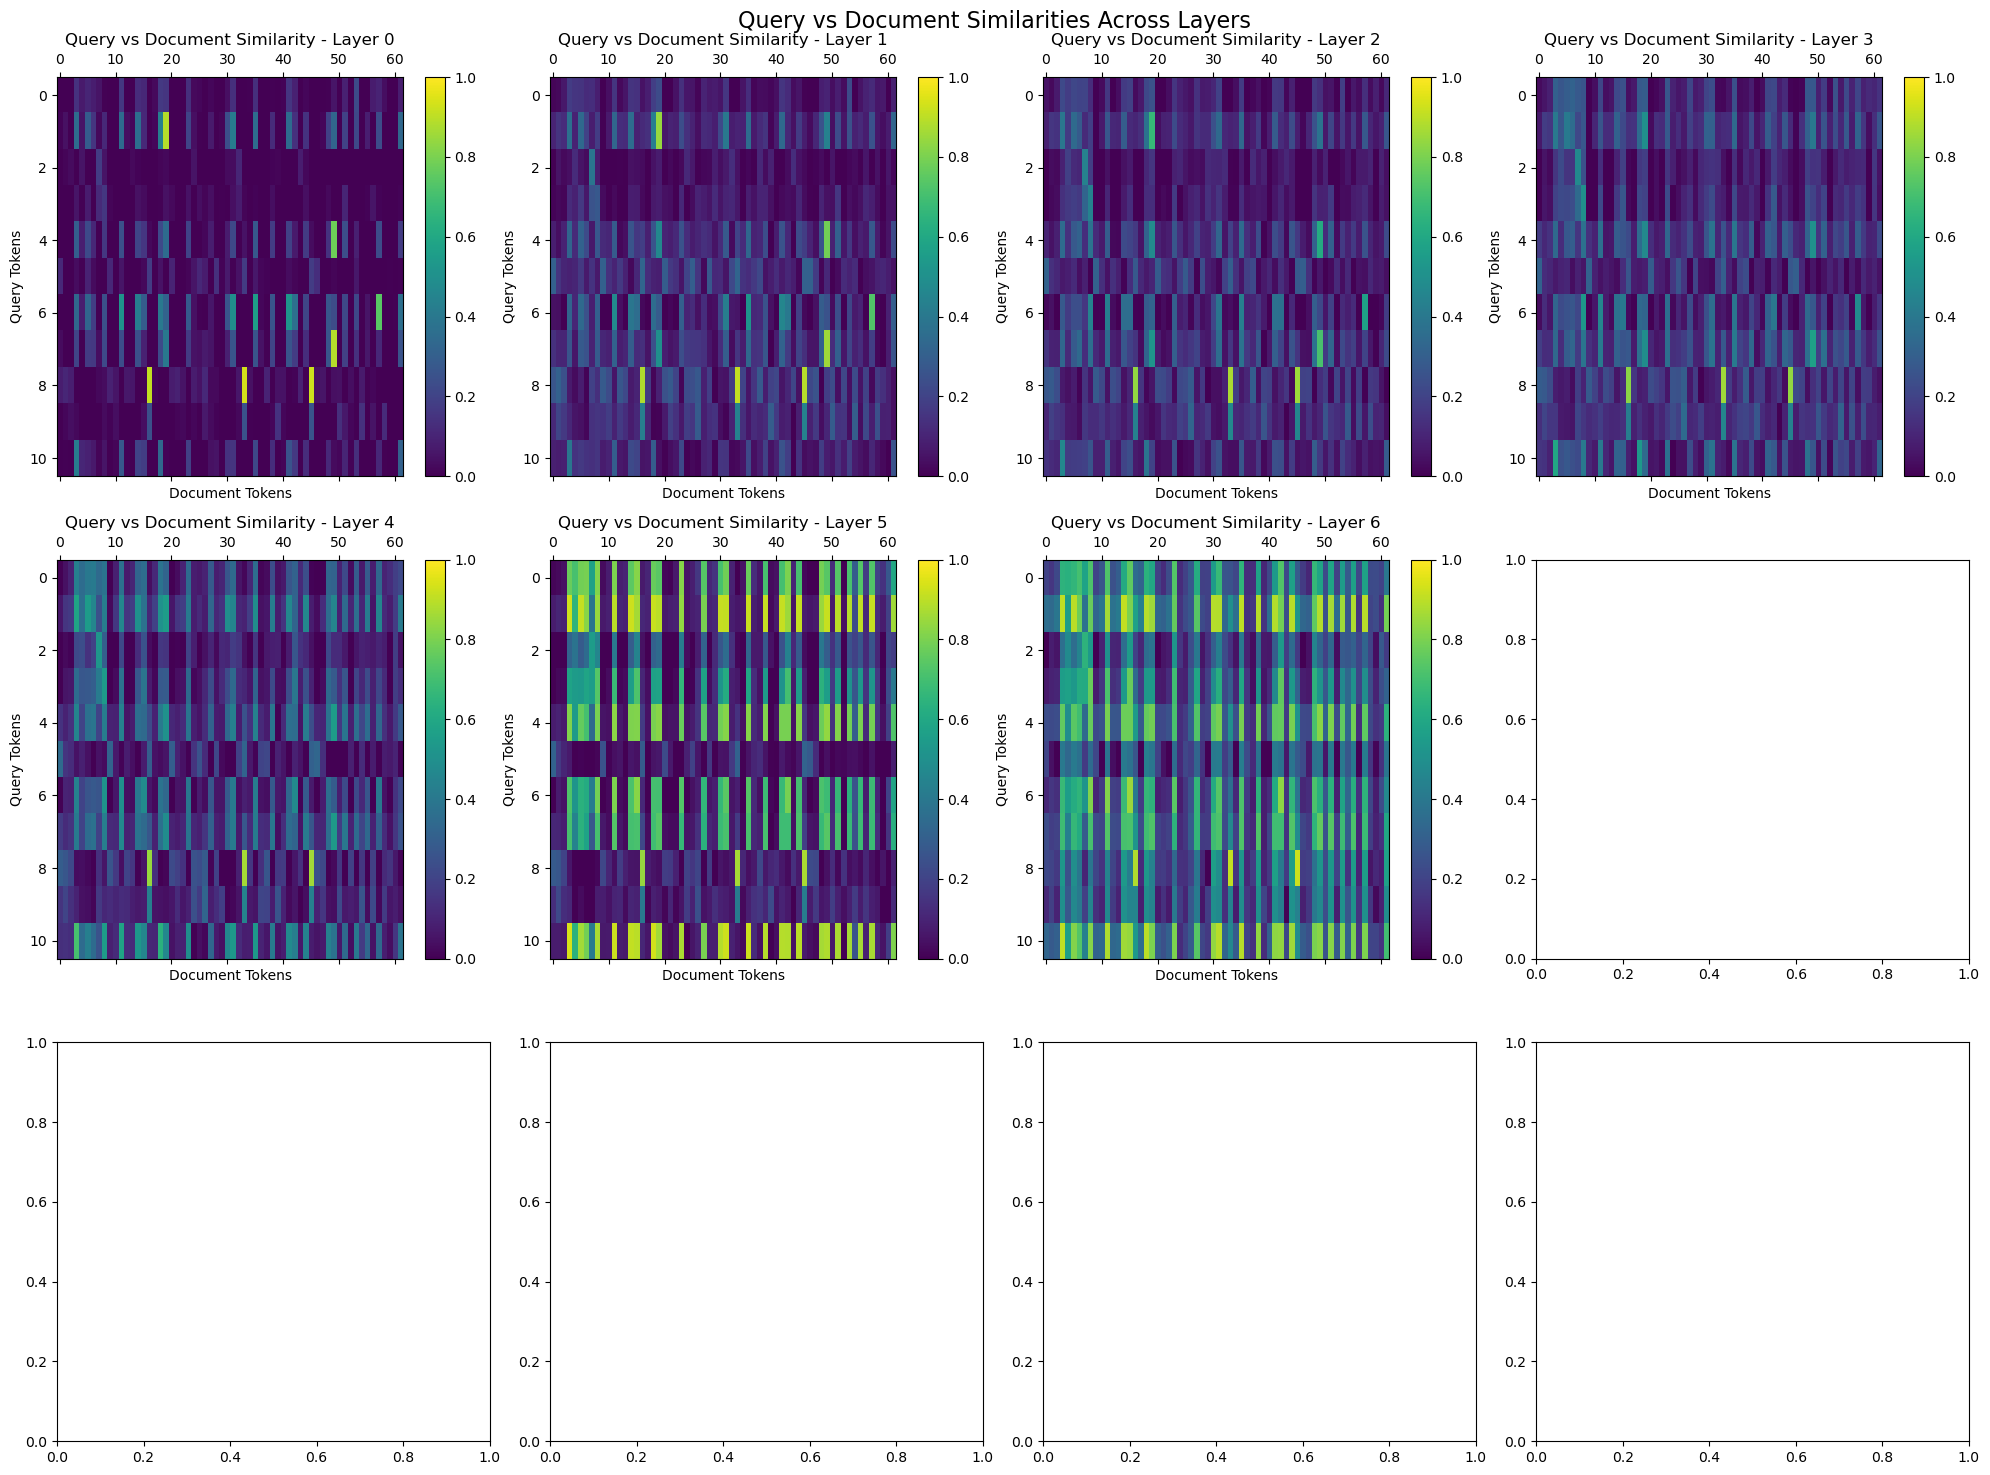

In [24]:
#SIMILARITY

# Determine indices of query and document tokens
sep_token_id_NEG = dual_encoder_tokenizer.sep_token_id  # Get the ID of [SEP]
input_ids_NEG_list = input_ids_NEG[0].tolist()    

query_indices = range(1, input_ids_NEG_list.index(sep_token_id_NEG))  

# Document tokens are between the first [SEP] and the second [SEP]
doc_indices = range(input_ids_NEG_list.index(sep_token_id_NEG) + 1, len(input_ids_NEG_list) - 1)

from sklearn.metrics.pairwise import cosine_similarity


similarities_NEG = []

for layer in range(len(hidden_states_NEG)):
    layer_embeddings = hidden_states_NEG[layer][0].detach().numpy()
    query_embeddings = layer_embeddings[query_indices]
    doc_embeddings = layer_embeddings[doc_indices]

    # Compute similarity matrix
    similarity_matrix_NEG = cosine_similarity(query_embeddings, doc_embeddings)
    similarities_NEG.append(similarity_matrix_NEG)


import matplotlib.pyplot as plt
import numpy as np

# Assuming similarities is a list of similarity matrices (one for each layer)
rows, cols = 3, 4  # Adjust based on the number of layers
fig, ax_full = plt.subplots(rows, cols, figsize=(20, 15))

layer = 0
for r in range(rows):
    for c in range(cols):
        if layer >= len(similarities_NEG):  # Avoid indexing beyond available layers
            break
        
        ax = ax_full[r, c]
        similarity_matrix_NEG = similarities_NEG[layer]
        
        # Plot similarity matrix using matshow (alternative to heatmap)
        cax = ax.matshow(similarity_matrix_NEG, cmap="viridis", aspect='auto', vmin=0, vmax=1)

        ax.set_title(f"Query vs Document Similarity - Layer {layer}")
        ax.set_xlabel("Document Tokens")
        ax.set_ylabel("Query Tokens")
        
        # Add colorbar to the side
        fig.colorbar(cax, ax=ax)

        layer += 1

plt.suptitle("Query vs Document Similarities Across Layers", fontsize=16)
plt.tight_layout()
plt.show()
fig.savefig("self-att-visualizations/SimilarityDual-NEG.png")


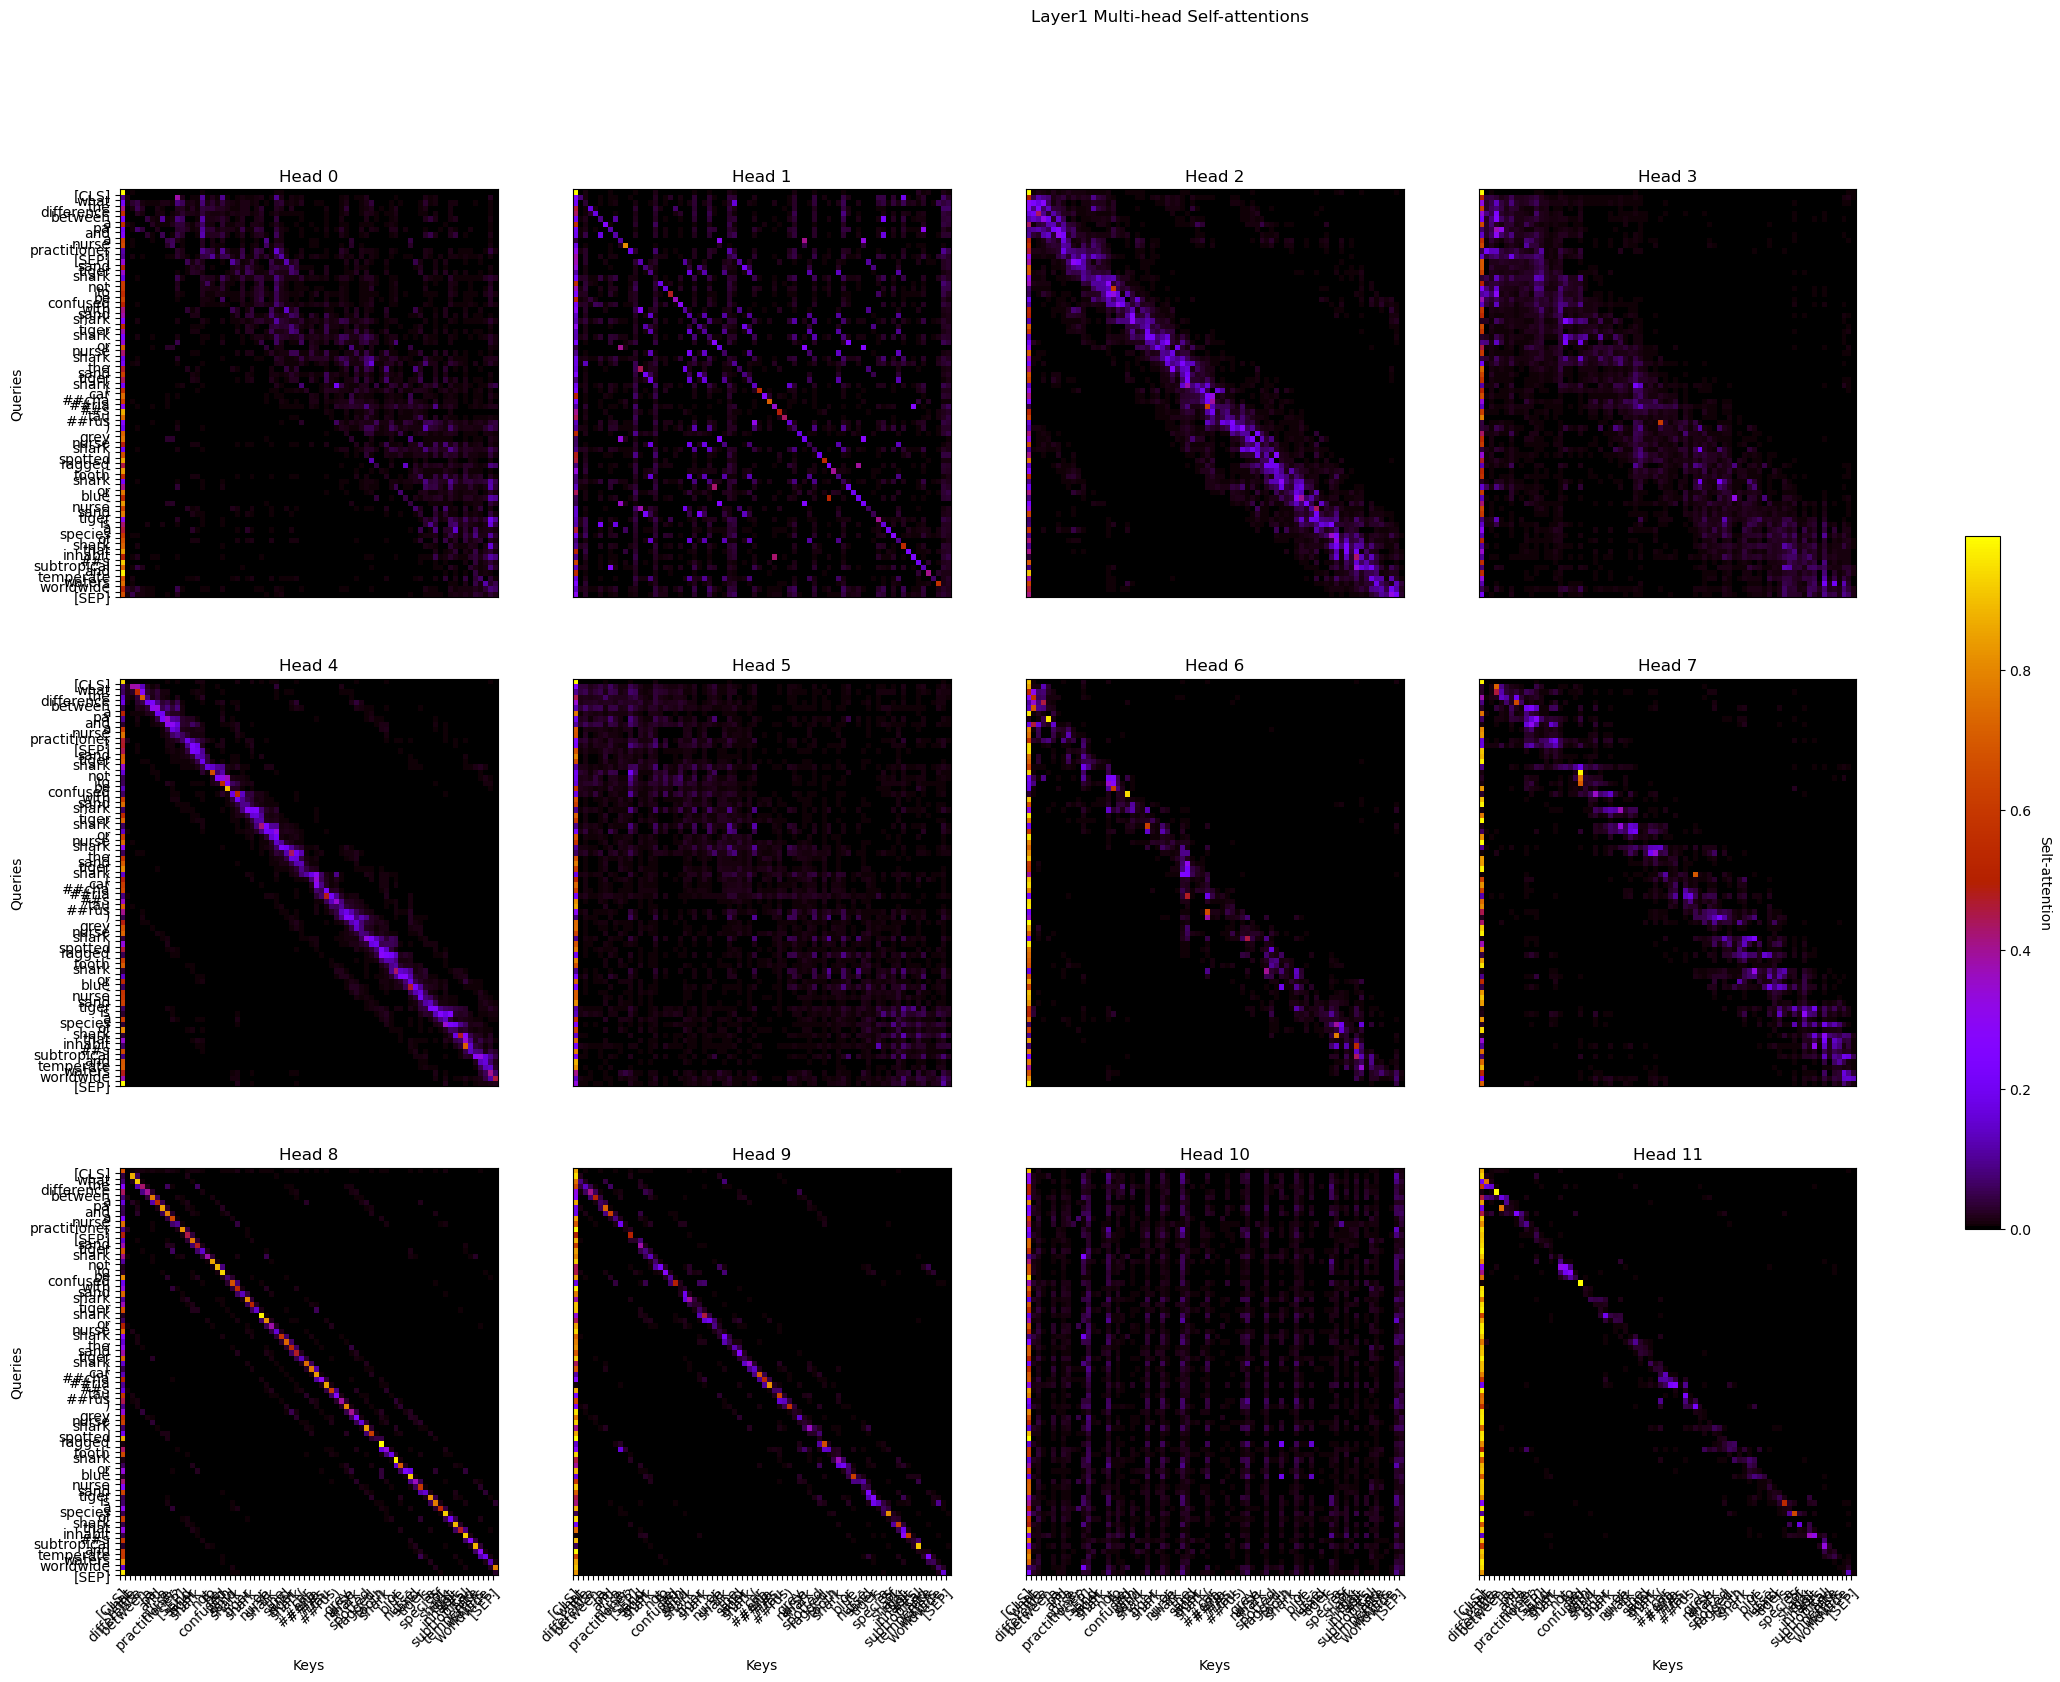

In [25]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

layer = 1

rows = 3
cols = 4
fig, ax_full = plt.subplots(rows, cols)
fig.set_figheight(rows*6)
fig.set_figwidth(cols*6+4)
plt.rcParams.update({'font.size': 10})


j = 0
for r in range(rows):
    for c in range(cols):
        
        ax = ax_full[r,c]
        
        sattention_NEG = attention_NEG[layer][0][j].numpy()
        sattention_NEG = np.flip(sattention_NEG, 0)
        
        plt.rcParams.update({'font.size': 10})

        im = ax.pcolormesh(sattention_NEG, cmap='gnuplot')

        # Show all ticks and label them with the respective list entries
        ax.set_title("Head " + str(j))
        ax.set_yticks(np.arange(len(input_tokens_NEG_list)))
        if c == 0:
            ax.set_yticklabels(reversed(input_tokens_NEG_list))
            ax.set_ylabel("Queries")
        else:
            ax.set_yticks([])

        ax.set_xticks(np.arange(len(input_tokens_NEG_list)))
        if r == rows-1:
            ax.set_xticklabels(input_tokens_NEG_list)
            ax.set_xlabel("Keys")
            
            # Rotate the tick labels and set their alignment.
            plt.setp(ax.get_xticklabels(), rotation=45, ha="right",
                     rotation_mode="anchor")
        else:
            ax.set_xticks([])

            
        # Loop over data dimensions and create text annotations.
        j = j + 1

fig.suptitle("Layer" + str(layer) + " Multi-head Self-attentions")
cbar = fig.colorbar(im, ax=ax_full, location='right', shrink=0.5)
cbar.ax.set_ylabel("Selt-attention", rotation=-90, va="bottom")

#plt.figure(figsize=(x,y))

plt.show()
fig.savefig("self-att-visualizations/HeadVisualizationDual-NEG.png")